In [1]:
import pandas as pd
import numpy as np

# Load dataset
file_path = r"F:\25.2F HND\ML CW\fish_price_ready_for_model.csv"

df = pd.read_csv(file_path)

print("=" * 80)
print("FISH PRICE ML DATASET")
print("=" * 80)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))

print("\nDataset information:")
df.info()

FISH PRICE ML DATASET
Rows: 978
Columns: 9

Column names:
['Species', 'MarketType', 'Year', 'MonthNumber', 'Week', 'Price_2025', 'Price_LastWeek', 'Change_LastYear_%', 'Price_Current']

First 10 rows:


,Species,MarketType,Year,MonthNumber,Week,Price_2025,Price_LastWeek,Change_LastYear_%,Price_Current
0,Barracuda(L),Consumer,2026,3,1.0,2170.00,2580.0,14.7,2490.00
1,Big eye scade,Consumer,2026,3,1.0,1133.33,1420.0,15.6,1310.00
2,Cuttle fish,Consumer,2026,3,1.0,2160.00,2200.0,2.3,2210.00
3,Frigate tuna,Consumer,2026,3,1.0,970.00,1315.0,28.9,1250.00
4,Ginnati Paraw,Consumer,2026,3,1.0,1280.00,1680.0,22.7,1570.00
5,Herrings,Consumer,2026,3,1.0,1230.00,1260.0,2.1,1204.00
6,Indian Mackerel,Consumer,2026,3,1.0,1020.00,1430.0,31.4,1340.00
7,Indian Scad,Consumer,2026,3,1.0,920.00,1140.0,8.4,997.50
8,Katuwalla,Consumer,2026,3,1.0,720.00,740.0,6.5,766.67
9,Kawakawa,Consumer,2026,3,1.0,1066.67,1320.0,18.1,1260.00



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 978 entries, 0 to 977
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Species            978 non-null    object 
 1   MarketType         978 non-null    object 
 2   Year               978 non-null    int64  
 3   MonthNumber        978 non-null    int64  
 4   Week               978 non-null    float64
 5   Price_2025         978 non-null    float64
 6   Price_LastWeek     978 non-null    float64
 7   Change_LastYear_%  978 non-null    float64
 8   Price_Current      978 non-null    float64
dtypes: float64(5), int64(2), object(2)
memory usage: 68.9+ KB


In [2]:
print("=" * 80)
print("MISSING VALUES")
print("=" * 80)

print(df.isnull().sum())

MISSING VALUES
Species              0
MarketType           0
Year                 0
MonthNumber          0
Week                 0
Price_2025           0
Price_LastWeek       0
Change_LastYear_%    0
Price_Current        0
dtype: int64


In [3]:
print("=" * 80)
print("TARGET VARIABLE: Price_Current")
print("=" * 80)

print(df["Price_Current"].describe())

TARGET VARIABLE: Price_Current
count     978.000000
mean     1653.560930
std       835.053969
min         0.000000
25%      1076.250000
50%      1490.000000
75%      2132.140000
max      4490.000000
Name: Price_Current, dtype: float64


In [4]:
print("=" * 80)
print("MARKET TYPE")
print("=" * 80)

print(df["MarketType"].value_counts())

MARKET TYPE
MarketType
Wholesale    536
Consumer     442
Name: count, dtype: int64


In [5]:
print("=" * 80)
print("SPECIES")
print("=" * 80)

print("Number of species:", df["Species"].nunique())

print("\nSpecies:")
for species in sorted(df["Species"].unique()):
    print(species)

SPECIES
Number of species: 31

Species:
Anchovy
Barracuda(L)
Big eye scade
Cuttle fish
Frigate tuna
Ginnati Paraw
Herrings
Indian Anchovies
Indian Mackerel
Indian Scad
Katuwalla
Kawakawa
Marlins
Needle fish
Pony fish
Prawns
Rainbow Runner
Red Bream(L)
Rock fish (L)
Rock fish (S)
Sail fish
Sardinella
Sea Crabs(L)
Seer
Shark
Skipjack tuna
Threadfin Bream
Tilapia
Trevally (L)
White Sardinella
Yellowfin tuna


In [6]:
print("=" * 80)
print("MONTHS")
print("=" * 80)

print(df["MonthNumber"].value_counts().sort_index())

MONTHS
MonthNumber
3    226
4    212
5    208
6    108
7    224
Name: count, dtype: int64


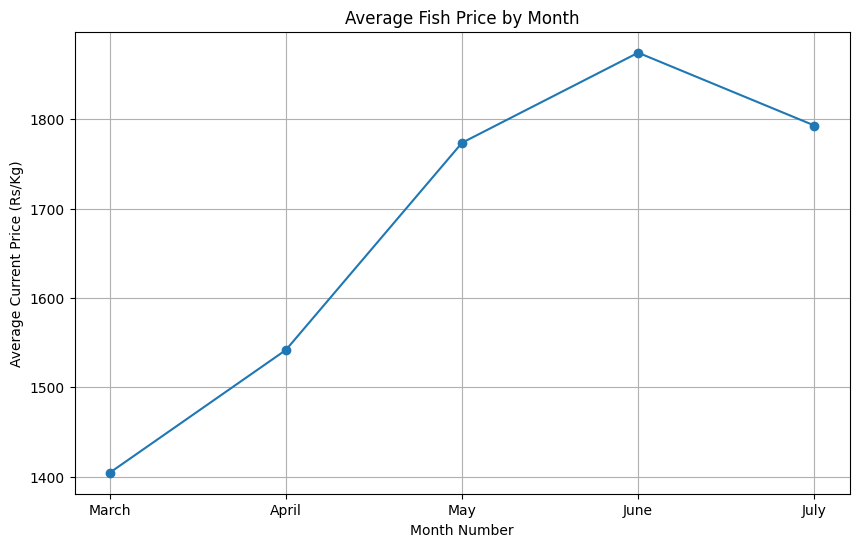

In [7]:
import matplotlib.pyplot as plt

monthly_price = (
    df.groupby("MonthNumber", observed=True)["Price_Current"]
      .mean()
)

plt.figure(figsize=(10, 6))

plt.plot(
    monthly_price.index,
    monthly_price.values,
    marker="o"
)

plt.xlabel("Month Number")
plt.ylabel("Average Current Price (Rs/Kg)")
plt.title("Average Fish Price by Month")

plt.xticks(
    [3, 4, 5, 6, 7],
    ["March", "April", "May", "June", "July"]
)

plt.grid(True)
plt.show()

In [8]:
numeric_columns = [
    "Year",
    "MonthNumber",
    "Week",
    "Price_2025",
    "Price_LastWeek",
    "Change_LastYear_%",
    "Price_Current"
]

correlation = df[numeric_columns].corr()

print(correlation)

                   Year  MonthNumber      Week  Price_2025  Price_LastWeek  \
Year                NaN          NaN       NaN         NaN             NaN   
MonthNumber         NaN     1.000000 -0.074458    0.152987        0.192952   
Week                NaN    -0.074458  1.000000    0.013340       -0.028332   
Price_2025          NaN     0.152987  0.013340    1.000000        0.903909   
Price_LastWeek      NaN     0.192952 -0.028332    0.903909        1.000000   
Change_LastYear_%   NaN     0.112422 -0.110232   -0.270512       -0.212773   
Price_Current       NaN     0.185672 -0.037772    0.906463        0.977614   

                   Change_LastYear_%  Price_Current  
Year                             NaN            NaN  
MonthNumber                 0.112422       0.185672  
Week                       -0.110232      -0.037772  
Price_2025                 -0.270512       0.906463  
Price_LastWeek             -0.212773       0.977614  
Change_LastYear_%           1.000000      -0.166794

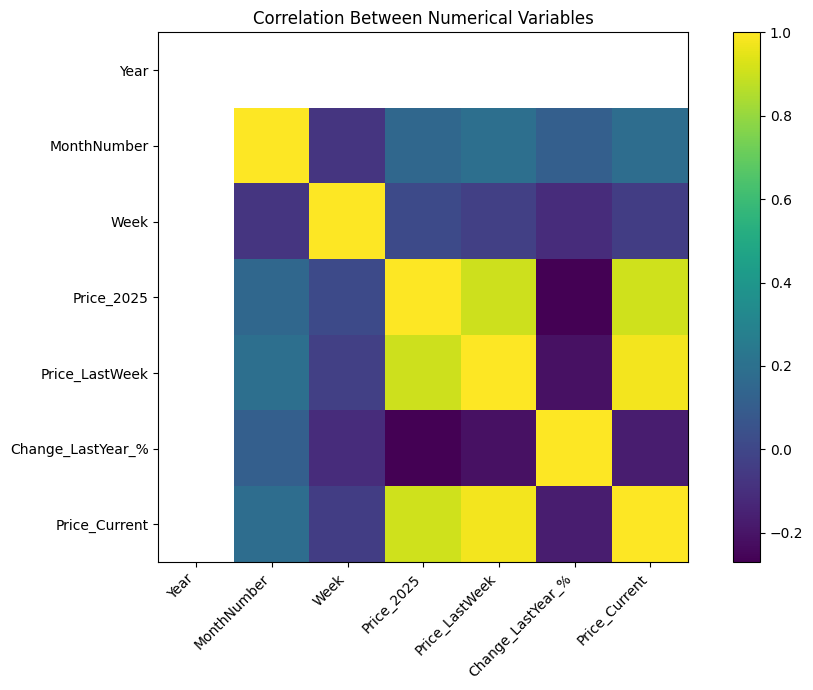

In [9]:
plt.figure(figsize=(10, 7))

plt.imshow(
    correlation,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Between Numerical Variables")

plt.tight_layout()
plt.show()

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split

# ============================================================
# 1. LOAD DATASET
# ============================================================

file_path = r"F:\25.2F HND\ML CW\fish_price_ready_for_model.csv"

df = pd.read_csv(file_path)

print("=" * 70)
print("DATASET LOADED")
print("=" * 70)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# 2. CHECK DATA
# ============================================================

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

print(df.isnull().sum())


# ============================================================
# 3. DEFINE TARGET VARIABLE
# ============================================================

# We want to predict the current fish price
target = "Price_Current"

print("\nTarget variable:", target)


# ============================================================
# 4. SELECT FEATURES
# ============================================================

features = [
    "Year",
    "Month",
    "Week",
    "MarketType",
    "Species",
    "Price_LastWeek"
]

X = df[features].copy()
y = df[target].copy()


# ============================================================
# 5. CONVERT CATEGORICAL VARIABLES
# ============================================================

# Convert Month and MarketType and Species
# into numerical dummy variables

X = pd.get_dummies(
    X,
    columns=["Month", "MarketType", "Species"],
    drop_first=True
)


# ============================================================
# 6. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# ============================================================
# 7. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("TRAINING / TESTING SPLIT")
print("=" * 70)

print("Total records :", len(df))
print("Training data :", len(X_train))
print("Testing data  :", len(X_test))

print("\nTraining percentage:",
      round(len(X_train) / len(df) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test) / len(df) * 100, 2), "%")


# ============================================================
# 8. CHECK SHAPES
# ============================================================

print("\nX_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


# ============================================================
# 9. CHECK TARGET VALUES
# ============================================================

print("\n" + "=" * 70)
print("TARGET VARIABLE")
print("=" * 70)

print("Training target:")
print(y_train.head())

print("\nTesting target:")
print(y_test.head())


print("\n" + "=" * 70)
print("TRAINING / TESTING SPLIT COMPLETED")
print("=" * 70)

DATASET LOADED
Rows: 978
Columns: 9

Columns:
['Species', 'MarketType', 'Year', 'MonthNumber', 'Week', 'Price_2025', 'Price_LastWeek', 'Change_LastYear_%', 'Price_Current']

MISSING VALUES
Species              0
MarketType           0
Year                 0
MonthNumber          0
Week                 0
Price_2025           0
Price_LastWeek       0
Change_LastYear_%    0
Price_Current        0
dtype: int64

Target variable: Price_Current


KeyError: "['Month'] not in index"